# Using Clustering and PCA to Predict TV Show Attributes from Visual Features of Posters

In [1]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [2]:
def get_random_images(filepath, n=1000):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [3]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [4]:
def get_imdb_data(imdb_id, imdbCSV):
    """Get IMDB data from the specified CSV file."""
    try:
        tmpDF = pd.read_csv(imdbCSV)
        row = tmpDF[tmpDF['imdb_id'] == imdb_id]
        
        # Access first row values using iloc[0] and column names
        
        #genres = [genre.strip() for genre in row['genres'].iloc[0].split(',')]
        
        show_data = {
            'imdb_id': imdb_id,
            'title': row['title'].iloc[0],
            'rating': row['rating'].iloc[0],
            'rating_count': row['rating_count'].iloc[0],
            'content_rating': row['content_rating'].iloc[0] if 'content_rating' in row.columns else '',
            'date_published': row['date_published'].iloc[0],
            #'genres': genres
        }
        return show_data
    except Exception as e:
        #print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [5]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [6]:
def create_dataset(image_folder, imdbCSV):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id, imdbCSV)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            color_features = extract_color_features(img_path)

            if color_features is not None:
                # Extract year from date_published
                tempyear = show_data['date_published'][:4]
                
                # Get genres and create one-hot encoding
                #genres = show_data['genres']
                
                # Combine all features
                combined_data = {
                    'imdb_id': imdb_id,
                    'r_mean': color_features[0],
                    'g_mean': color_features[1],
                    'b_mean': color_features[2],
                    'w_mean': color_features[3],
                    'rating': show_data['rating'],
                    'year': int(tempyear),
                    #'genres': genres
                }
                data.append(combined_data)
    
    # Create DataFrame
    df = pd.DataFrame(data)
    
    # Create one-hot encoding for genres
    #all_genres = []
    #for genres in df['genres']:
        #all_genres.extend(genres)
    #unique_genres = sorted(list(set(all_genres)))
    
    # Create genre columns
    #for genre in unique_genres:
    #    df[f'genre_{genre}'] = df['genres'].apply(lambda x: 1 if genre in x else 0)
    
    # Drop the original genres column
    #df = df.drop('genres', axis=1)
    
    # Save dataset
    df.to_csv('combined_data.csv', index=False)
    
    return df

In [ ]:
def perform_pca_analysis(df):
    """Perform PCA on features including metadata."""
    # Prepare feature matrix (exclude imdb_id)
    X = df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
     # Save the scaler
    joblib.dump(scaler, 'scaler.pkl')
    print("Scaler model saved as scaler.pkl")
    
    # Perform PCA
    pca = PCA()
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Find number of components needed for 80% variance
    n_components = np.argmax(cum_var_ratio >= 0.8) + 1
    
    # Save the PCA model
    joblib.dump(pca, 'pca_model.pkl')
    print(f"PCA model saved as pca_model.pkl with {n_components} components.")
    
    return pca, X_pca, n_components, X.columns

In [8]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

In [9]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [10]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(X_pca.shape[1])])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [11]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [12]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import matplotlib.pyplot as plt
    
    fig = plt.figure(figsize=(25, 10))
    
    # K-means
    ax1 = fig.add_subplot(151)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(152)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(153)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # GMM
    ax4 = fig.add_subplot(154)
    gmm = GaussianMixture(n_components=3, random_state=42)
    gmm_labels = gmm.fit_predict(X_pca[:, :n_components])
    scatter4 = ax4.scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='viridis')
    ax4.set_title('Gaussian Mixture Model')
    ax4.set_xlabel('PC1')
    ax4.set_ylabel('PC2')
    
    # BIRCH
    ax5 = fig.add_subplot(155)
    birch = Birch(n_clusters=3)
    birch_labels = birch.fit_predict(X_pca[:, :n_components])
    scatter5 = ax5.scatter(X_pca[:, 0], X_pca[:, 1], c=birch_labels, cmap='viridis')
    ax5.set_title('BIRCH Clustering')
    ax5.set_xlabel('PC1')
    ax5.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    fig.colorbar(scatter4, ax=ax4, label='Cluster')
    fig.colorbar(scatter5, ax=ax5, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [13]:
def analyze_clusters(X_pca, n_clusters_range=range(2, 7)):
    """
    Analyze clusters using Silhouette Score and Davies-Bouldin Index for different clustering methods.
    Returns results in tabular format.
    """
    from sklearn.metrics import silhouette_score, davies_bouldin_score
    from sklearn.cluster import KMeans, DBSCAN, Birch
    from sklearn.mixture import GaussianMixture
    from scipy.cluster.hierarchy import linkage, fcluster
    import pandas as pd
    import numpy as np
    
    # Initialize results storage
    results = []
    best_model = None
    best_score = -np.inf  # Track best silhouette score
    best_method = ""
    
    # K-means evaluation
    for n_clusters in n_clusters_range:
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        
        results.append({
            'Method': 'K-means',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
        
        # Track the best model based on Silhouette Score
        if score > best_score:
            best_score = score
            best_model = kmeans
            best_method = "K-Means"
    
    # Hierarchical evaluation
    for n_clusters in n_clusters_range:
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
        score = silhouette_score(X_pca, labels)
        
        results.append({
            'Method': 'Hierarchical',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
        
        if score > best_score:
            best_score = score
            best_model = Z  # Save linkage matrix for hierarchical clustering
            best_method = "Hierarchical"
    
    # DBSCAN evaluation
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    labels = dbscan.fit_predict(X_pca)
    
    # Only calculate scores if DBSCAN found more than one cluster
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    if n_clusters > 1:
        score = silhouette_score(X_pca, labels)
        results.append({
            'Method': 'DBSCAN',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
        
        if score > best_score:
            best_score = score
            best_model = dbscan
            best_method = "DBSCAN"
    
    # GMM evaluation
    for n_clusters in n_clusters_range:
        gmm = GaussianMixture(n_components=n_clusters, random_state=42)
        labels = gmm.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        
        results.append({
            'Method': 'GMM',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
        
        if score > best_score:
            best_score = score
            best_model = gmm
            best_method = "GMM"
    
    # BIRCH evaluation
    for n_clusters in n_clusters_range:
        birch = Birch(n_clusters=n_clusters)
        labels = birch.fit_predict(X_pca)
        score = silhouette_score(X_pca, labels)
        
        results.append({
            'Method': 'BIRCH',
            'n_clusters': n_clusters,
            'Silhouette Score': silhouette_score(X_pca, labels),
            'Davies-Bouldin Index': davies_bouldin_score(X_pca, labels)
        })
        
        if score > best_score:
            best_score = score
            best_model = birch
            best_method = "BIRCH"
    
    # Create DataFrame
    df_results = pd.DataFrame(results)
    
    # Format the metrics to 3 decimal places
    df_results['Silhouette Score'] = df_results['Silhouette Score'].round(3)
    df_results['Davies-Bouldin Index'] = df_results['Davies-Bouldin Index'].round(3)
    
    # Print formatted tables
    print("\nClustering Evaluation Results:")
    print(df_results.to_string(index=False))
    
    # Create summary of best results
    print("\nBest Results:")
    best_silhouette = df_results.loc[df_results['Silhouette Score'].idxmax()]
    best_davies = df_results.loc[df_results['Davies-Bouldin Index'].idxmin()]
    
    summary = pd.DataFrame([
        {
            'Metric': 'Best Silhouette Score',
            'Method': best_silhouette['Method'],
            'n_clusters': best_silhouette['n_clusters'],
            'Score': best_silhouette['Silhouette Score']
        },
        {
            'Metric': 'Best Davies-Bouldin Index',
            'Method': best_davies['Method'],
            'n_clusters': best_davies['n_clusters'],
            'Score': best_davies['Davies-Bouldin Index']
        }
    ])
    
    print(summary.to_string(index=False))
    
    # Save the best clustering model
    if best_model is not None:
        joblib.dump(best_model, 'best_cluster_model.pkl')
        print(f"Best Model: {best_method} with Silhouette Score: {best_score:.3f} saved as best_cluster_model.pkl.")
    
    return df_results

In [14]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdbCSV = "tv_shows_data.csv"
combined_df = create_dataset(IMAGE_FOLDER, imdbCSV)   

Step 1: Gathering data...


In [15]:
print("\nIMDB Data Sample:")
combined_df.head()


IMDB Data Sample:


,imdb_id,r_mean,g_mean,b_mean,w_mean,rating,year
0,tt20102648,70.787282,84.458254,94.201783,42.865660,8.1,2022
1,tt0045447,166.763884,165.189267,167.461987,43.503459,8.2,1953
2,tt1957484,183.816831,172.026733,178.066566,63.985916,6.1,2011
3,tt1354462,73.128773,82.748366,60.511759,38.812172,7.3,2009
4,tt1935719,122.135403,96.673151,89.020953,38.701672,8.0,2011


In [18]:
# Perform PCA analysis
print("\nStep 2: Performing PCA analysis...")
pca, X_pca, n_components, feature_names = perform_pca_analysis(combined_df)


Step 2: Performing PCA analysis...
Scaler model saved as scaler.pkl


UnboundLocalError: cannot access local variable 'n_components' where it is not associated with a value

In [ ]:
# Display PCA results
print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
print(evr)


Explained variance ratios:
                     Explained Variance Ratio
Principal Component                          
PC1                                  0.547340
PC2                                  0.169052
PC3                                  0.163790
PC4                                  0.056924
PC5                                  0.051193
PC6                                  0.011701


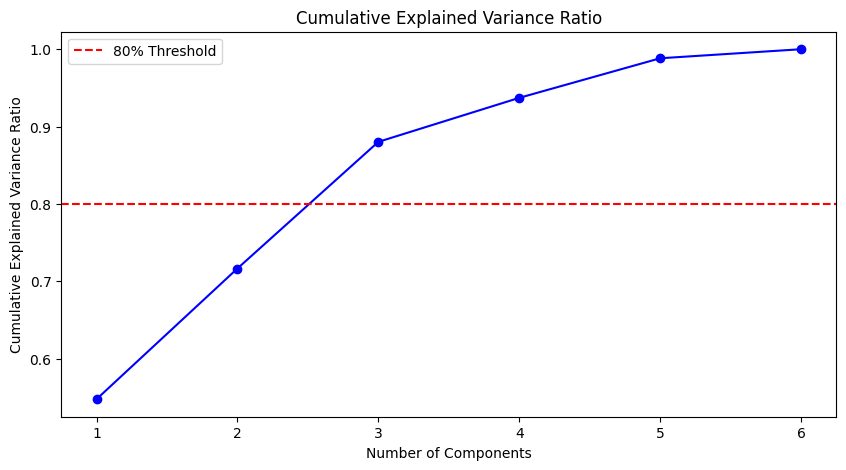

In [ ]:
plot_cumulative_variance(pca)

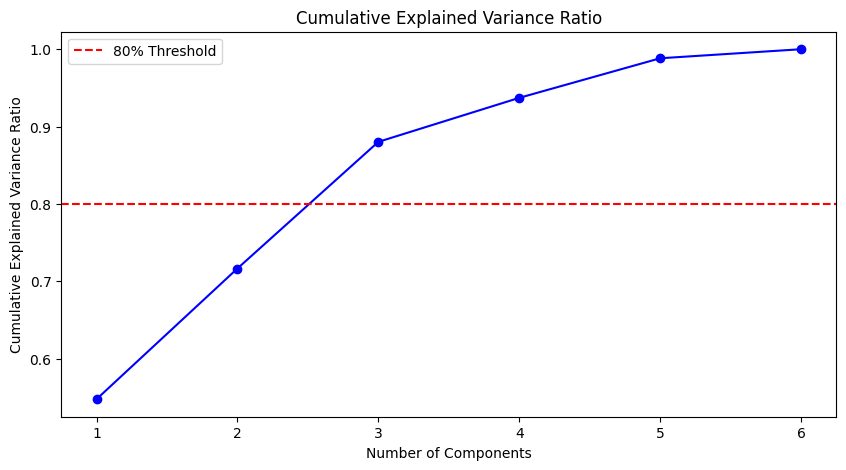

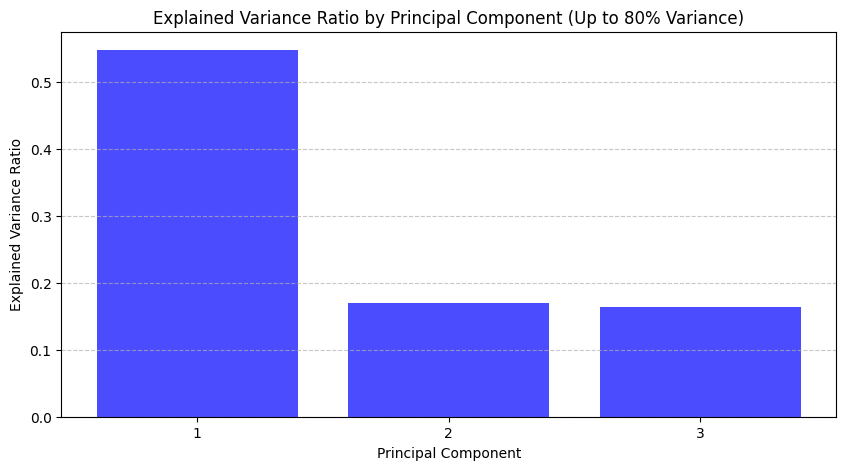

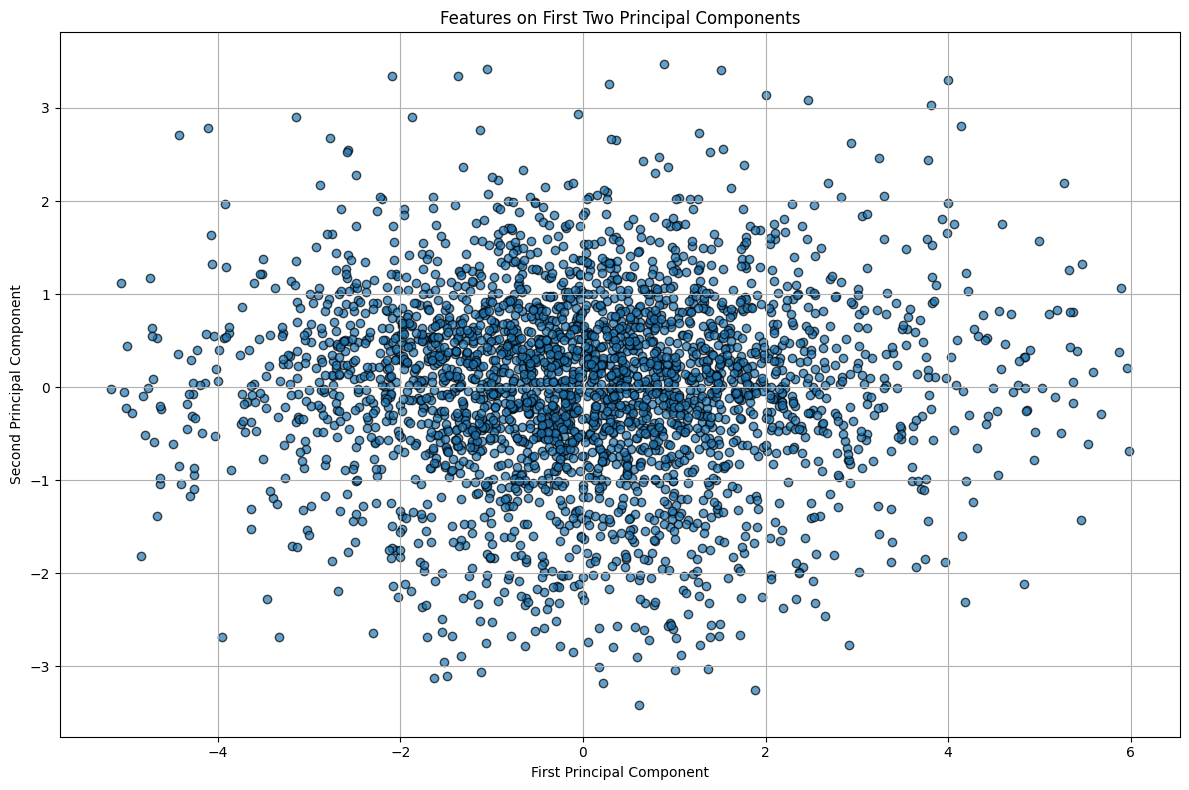

In [ ]:
# Plot PCA analysis
plot_cumulative_variance(pca)
plot_explained_variance(pca, n_components)
plot_pca_features(pca, X_pca, n_components)

In [ ]:
# Show feature loadings
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
print("\nFeature Loadings:")
print(loadings_df)
print("\nTop Feature Contributions to PC1:")
print(loadings_df.sort_values(by="PC1", ascending=False).head(10))


Feature Loadings:
             PC1       PC2       PC3
r_mean  0.891622 -0.030276  0.024588
g_mean  0.958401 -0.022614  0.021007
b_mean  0.899358  0.019963  0.008475
w_mean  0.869729  0.011241  0.030388
rating -0.070446 -0.685365  0.724773
year   -0.037107  0.736867  0.675078

Top Feature Contributions to PC1:
             PC1       PC2       PC3
g_mean  0.958401 -0.022614  0.021007
b_mean  0.899358  0.019963  0.008475
r_mean  0.891622 -0.030276  0.024588
w_mean  0.869729  0.011241  0.030388
year   -0.037107  0.736867  0.675078
rating -0.070446 -0.685365  0.724773



Step 3: Performing clustering analysis...


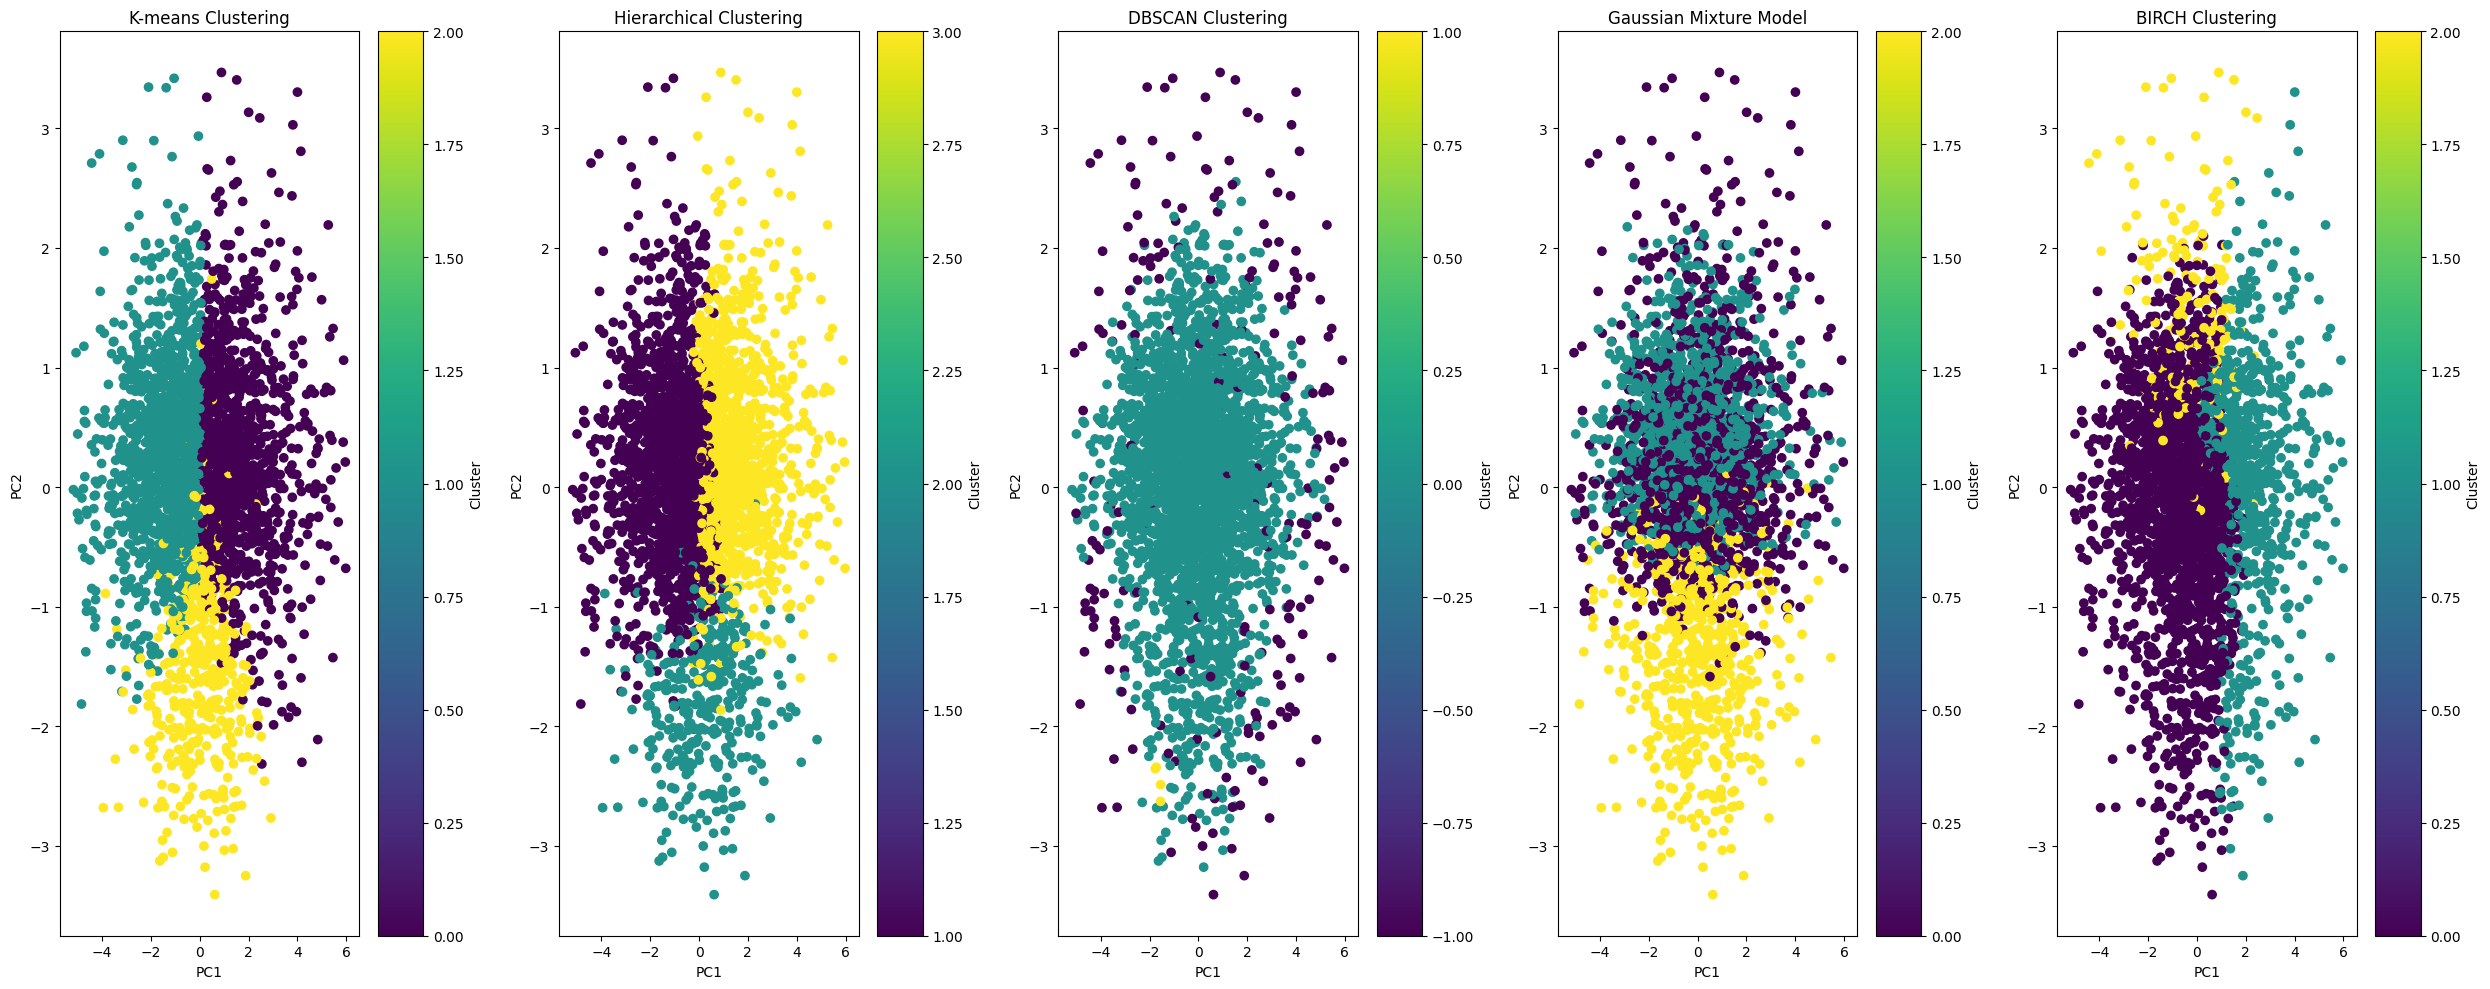

In [ ]:
# Perform clustering analysis
print("\nStep 3: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

In [ ]:
# After your PCA analysis
results = analyze_clusters(X_pca)


Clustering Evaluation Results:
      Method  n_clusters  Silhouette Score  Davies-Bouldin Index
     K-means           2             0.281                 1.300
     K-means           3             0.212                 1.474
     K-means           4             0.216                 1.429
     K-means           5             0.244                 1.207
     K-means           6             0.225                 1.219
Hierarchical           2             0.193                 1.460
Hierarchical           3             0.208                 1.472
Hierarchical           4             0.184                 1.427
Hierarchical           5             0.205                 1.275
Hierarchical           6             0.165                 1.326
      DBSCAN          23            -0.415                 1.887
         GMM           2             0.019                 6.591
         GMM           3             0.043                 4.544
         GMM           4             0.075                